# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

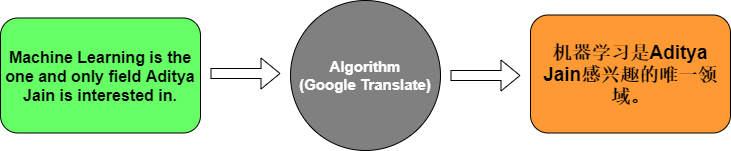

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.0000e+00 - loss: 2.4860 - val_accuracy: 0.0000e+00 - val_loss: 2.4873
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.1429 - loss: 2.4781 - val_accuracy: 0.0000e+00 - val_loss: 2.4892
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.5714 - loss: 2.4702 - val_accuracy: 0.0000e+00 - val_loss: 2.4912
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.5714 - loss: 2.4617 - val_accuracy: 0.0000e+00 - val_loss: 2.4935
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.5714 - loss: 2.4522 - val_accuracy: 0.0000e+00 - val_loss: 2.4960
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.5714 - loss: 2.4415 - val_accuracy: 0.0000e+00 - val_loss: 2.4989
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.5714 - loss: 2.4291 - val_accuracy: 0.0000e+00 - val_loss: 2.5022
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.5714 - loss: 2.4145 - val_accur

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 388ms/step
Input: How are you?
Translation: comment va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. The Embedding layer converts each word index into a dense numerical vector that represents the word.

2. The Encoder LSTM reads the English sentence and learns its context and meaning.

3. The Decoder LSTM uses the encoded information to generate the French translation word by word.

4. Softmax converts the output scores into probabilities for all French words, so the model can select the most likely word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

from google.colab import files
uploaded = files.upload()

In [9]:
import zipfile
import os

with zipfile.ZipFile("archive (10).zip", "r") as zip_ref:
    zip_ref.extractall("data")

print(os.listdir("data"))

['eng_-french.csv']


In [10]:
import pandas as pd

df = pd.read_csv("data/eng_-french.csv")

print(df.head())
print("\nColumn names:", df.columns.tolist())
print("Dataset shape:", df.shape)

  English words/sentences French words/sentences
0                     Hi.                 Salut!
1                    Run!                Cours !
2                    Run!               Courez !
3                    Who?                  Qui ?
4                    Wow!             Ça alors !

Column names: ['English words/sentences', 'French words/sentences']
Dataset shape: (175621, 2)


In [11]:
english_col = "English words/sentences"
french_col = "French words/sentences"

data = df[[english_col, french_col]].dropna().copy()
data.columns = ["english", "french"]

data["english"] = data["english"].astype(str).str.lower().str.strip()
data["french"] = data["french"].astype(str).str.lower().str.strip()

# Keep short sentence pairs so the model trains faster
data = data[
    (data["english"].str.split().str.len() <= 10) &
    (data["french"].str.split().str.len() <= 10)
].copy()

data = data.sample(n=10000, random_state=42).reset_index(drop=True)

# Mark the start and end of every French translation
data["french"] = "startseq " + data["french"] + " endseq"

print(data.head())
print("Number of training pairs:", len(data))

                                english  \
0           i took a day off last week.   
1            who do you know in boston?   
2                    silence is golden.   
3      don't worry. i'll be right back.   
4  whatever can go wrong will go wrong.   

                                              french  
0  startseq j'ai pris un jour de congé la semaine...  
1     startseq qui connaissez-vous à boston ? endseq  
2               startseq le silence est d'or. endseq  
3  startseq ne t'en fais pas ! je serai bientôt d...  
4   startseq tout ce qui peut foirer foirera. endseq  
Number of training pairs: 10000


In [12]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_VOCAB = 5000

eng_tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<OOV>")
fr_tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<OOV>")

eng_tokenizer.fit_on_texts(data["english"])
fr_tokenizer.fit_on_texts(data["french"])

eng_sequences = eng_tokenizer.texts_to_sequences(data["english"])
fr_sequences = fr_tokenizer.texts_to_sequences(data["french"])

max_eng_len = max(len(sentence) for sentence in eng_sequences)
max_fr_len = max(len(sentence) for sentence in fr_sequences)

eng_padded = pad_sequences(eng_sequences, maxlen=max_eng_len, padding="post")
fr_padded = pad_sequences(fr_sequences, maxlen=max_fr_len, padding="post")

print("English padded shape:", eng_padded.shape)
print("French padded shape:", fr_padded.shape)
print("Maximum English length:", max_eng_len)
print("Maximum French length:", max_fr_len)

English padded shape: (10000, 11)
French padded shape: (10000, 14)
Maximum English length: 11
Maximum French length: 14


In [13]:
from sklearn.model_selection import train_test_split

# French input: startseq + sentence
decoder_input_data = fr_padded[:, :-1]

# French target: the next word at each position
decoder_target_data = fr_padded[:, 1:]

eng_train, eng_test, dec_in_train, dec_in_test, dec_target_train, dec_target_test = train_test_split(
    eng_padded,
    decoder_input_data,
    decoder_target_data,
    test_size=0.2,
    random_state=42
)

print("English train shape:", eng_train.shape)
print("English test shape:", eng_test.shape)
print("Decoder input train shape:", dec_in_train.shape)
print("Decoder target train shape:", dec_target_train.shape)

English train shape: (8000, 11)
English test shape: (2000, 11)
Decoder input train shape: (8000, 13)
Decoder target train shape: (8000, 13)


In [14]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

EMBEDDING_DIM = 64
LSTM_UNITS = 128

# Encoder: reads the English sentence
encoder_inputs = Input(shape=(max_eng_len,), name="encoder_input")
encoder_embedding = Embedding(
    input_dim=MAX_VOCAB,
    output_dim=EMBEDDING_DIM,
    mask_zero=True,
    name="encoder_embedding"
)(encoder_inputs)

encoder_lstm = LSTM(LSTM_UNITS, return_state=True, name="encoder_lstm")
_, state_h, state_c = encoder_lstm(encoder_embedding)

# Decoder: generates the French translation
decoder_inputs = Input(shape=(max_fr_len - 1,), name="decoder_input")
decoder_embedding = Embedding(
    input_dim=MAX_VOCAB,
    output_dim=EMBEDDING_DIM,
    mask_zero=True,
    name="decoder_embedding"
)(decoder_inputs)

decoder_lstm = LSTM(
    LSTM_UNITS,
    return_sequences=True,
    return_state=True,
    name="decoder_lstm"
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedding,
    initial_state=[state_h, state_c]
)

decoder_dense = Dense(MAX_VOCAB, activation="softmax", name="output_softmax")
decoder_outputs = decoder_dense(decoder_outputs)

model = Model([encoder_inputs, decoder_inputs], decoder_outputs)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 11)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, 13)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, 11, 64)    │    320,000 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 11)        │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, 13, 64)    │    320,000 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 128),     │     98,816 │ encoder_embeddin… │
│                     │ (None, 128),      │            │ not_equal[0][0]   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 13, 128), │     98,816 │ decoder_embeddin… │
│                     │ (None, 128),      │            │ encoder_lstm[0][… │
│                     │ (None, 128)]      │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_softmax      │ (None, 13, 5000)  │    645,000 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,482,632 (5.66 MB)

 Trainable params: 1,482,632 (5.66 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    [eng_train, dec_in_train],
    dec_target_train,
    validation_data=([eng_test, dec_in_test], dec_target_test),
    epochs=5,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 75s 574ms/step - accuracy: 0.1919 - loss: 5.9221 - val_accuracy: 0.2733 - val_loss: 5.0256
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 71s 566ms/step - accuracy: 0.2810 - loss: 4.7732 - val_accuracy: 0.2985 - val_loss: 4.7221
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 82s 568ms/step - accuracy: 0.3038 - loss: 4.5395 - val_accuracy: 0.3090 - val_loss: 4.5916
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 71s 569ms/step - accuracy: 0.3134 - loss: 4.3892 - val_accuracy: 0.3171 - val_loss: 4.5030
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 81s 563ms/step - accuracy: 0.3204 - loss: 4.2721 - val_accuracy: 0.3241 - val_loss: 4.4226


Test Loss: 3.9767
Test Accuracy: 0.3755


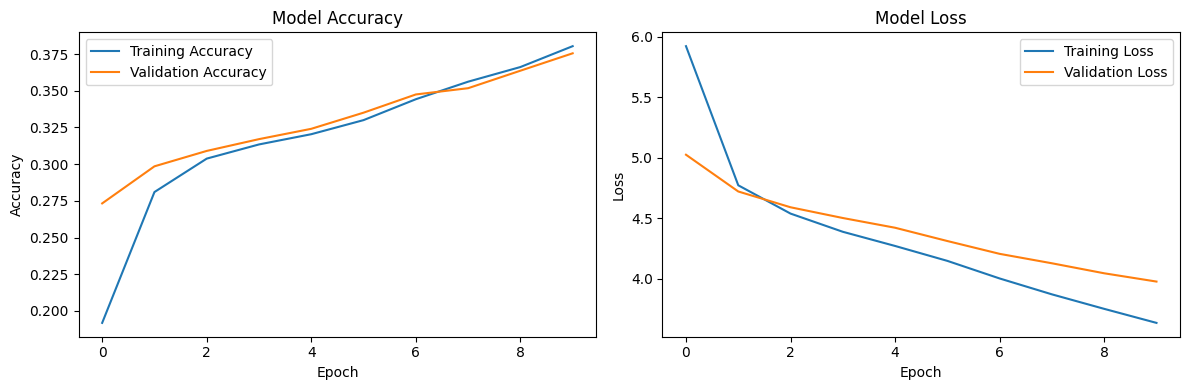

In [19]:
import matplotlib.pyplot as plt

test_loss, test_accuracy = model.evaluate(
    [eng_test, dec_in_test],
    dec_target_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [20]:
import numpy as np

# Encoder model for inference
encoder_model = Model(encoder_inputs, [state_h, state_c])

# Decoder model for inference
decoder_input_inf = Input(shape=(1,), name="decoder_input_inference")
state_input_h = Input(shape=(LSTM_UNITS,), name="state_h_inference")
state_input_c = Input(shape=(LSTM_UNITS,), name="state_c_inference")

decoder_embedding_inf = model.get_layer("decoder_embedding")(decoder_input_inf)

decoder_output_inf, state_h_inf, state_c_inf = model.get_layer("decoder_lstm")(
    decoder_embedding_inf,
    initial_state=[state_input_h, state_input_c]
)

decoder_output_inf = model.get_layer("output_softmax")(decoder_output_inf)

decoder_model = Model(
    [decoder_input_inf, state_input_h, state_input_c],
    [decoder_output_inf, state_h_inf, state_c_inf]
)

# French word index reversed: number -> word
reverse_fr_word_index = {
    index: word for word, index in fr_tokenizer.word_index.items()
}

start_token = fr_tokenizer.word_index["startseq"]
end_token = fr_tokenizer.word_index["endseq"]
oov_token = fr_tokenizer.word_index.get(fr_tokenizer.oov_token)

def translate(sentence):
    sentence = sentence.lower().strip()

    sequence = eng_tokenizer.texts_to_sequences([sentence])
    encoder_input = pad_sequences(
        sequence,
        maxlen=max_eng_len,
        padding="post"
    )

    states = encoder_model.predict(encoder_input, verbose=0)
    target_sequence = np.array([[start_token]])

    translated_words = []

    for _ in range(max_fr_len - 1):
        output, h, c = decoder_model.predict(
            [target_sequence] + states,
            verbose=0
        )

        predicted_index = int(np.argmax(output[0, -1, :]))

        if predicted_index in [0, end_token, oov_token]:
            break

        predicted_word = reverse_fr_word_index.get(predicted_index, "")

        if predicted_word != "startseq":
            translated_words.append(predicted_word)

        target_sequence = np.array([[predicted_index]])
        states = [h, c]

    return " ".join(translated_words)

test_sentences = [
    "how are you?",
    "thank you.",
    "where is my order?"
]

for sentence in test_sentences:
    print(f"English: {sentence}")
    print(f"French: {translate(sentence)}")
    print()

English: how are you?
French: c'est ce que vous

English: thank you.
French: c'est

English: where is my order?
French: le



In [18]:
more_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_extra = model.fit(
    [eng_train, dec_in_train],
    dec_target_train,
    validation_data=([eng_test, dec_in_test], dec_target_test),
    epochs=5,
    batch_size=64,
    callbacks=[more_early_stopping],
    verbose=1
)

for key in history.history:
    history.history[key].extend(history_extra.history[key])

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 72s 576ms/step - accuracy: 0.3300 - loss: 4.1490 - val_accuracy: 0.3351 - val_loss: 4.3129
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 72s 573ms/step - accuracy: 0.3442 - loss: 4.0037 - val_accuracy: 0.3475 - val_loss: 4.2071
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 81s 568ms/step - accuracy: 0.3562 - loss: 3.8726 - val_accuracy: 0.3518 - val_loss: 4.1292
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 82s 567ms/step - accuracy: 0.3662 - loss: 3.7528 - val_accuracy: 0.3637 - val_loss: 4.0465
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 71s 565ms/step - accuracy: 0.3804 - loss: 3.6369 - val_accuracy: 0.3755 - val_loss: 3.9781


### Task 2 Conclusion

An English-to-French Seq2Seq Encoder–Decoder LSTM model was trained using 10,000 sentence pairs from the dataset. The model generated French outputs for the test sentences. However, the translations were still limited because the model was trained on a small sample, used a limited vocabulary, and did not use an attention mechanism. Training with more data and using attention or Transformer-based models could improve translation quality.